# Fit pupil ellipse

Load model, fit an ellipse on the predicted mask and retrieve pupil center

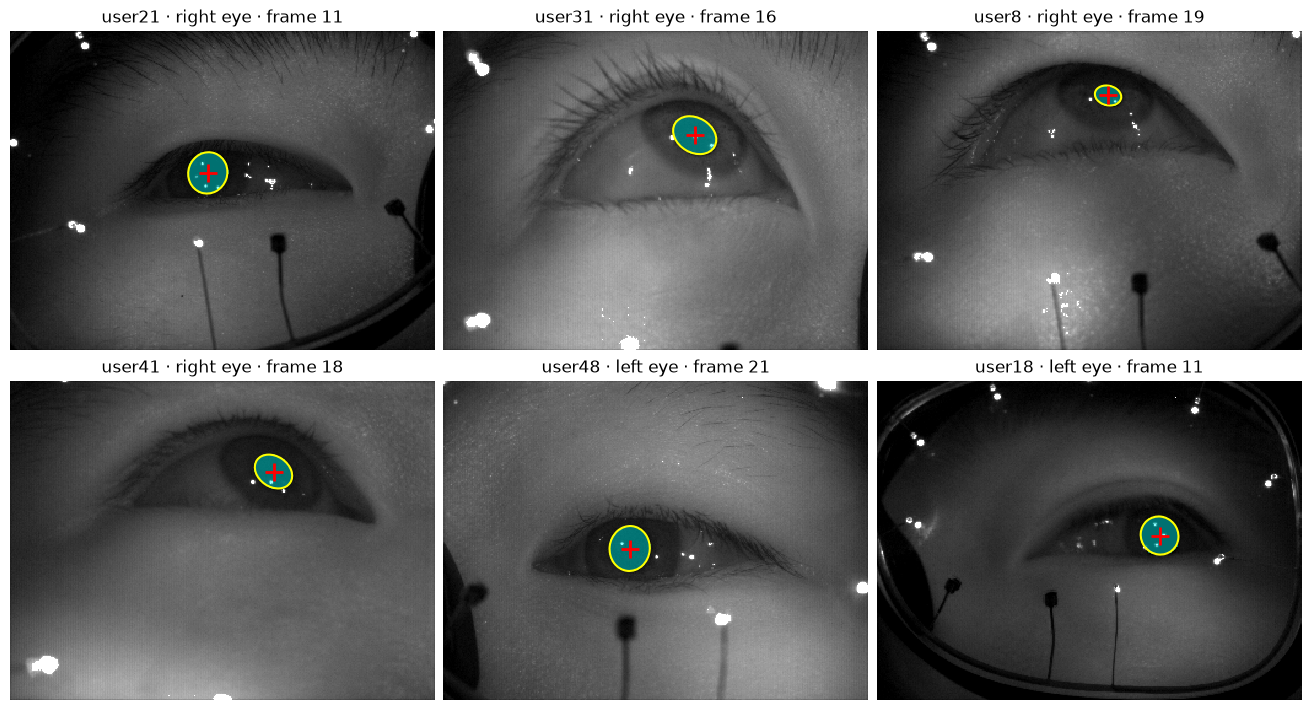

In [ ]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras

import cv2
from matplotlib.patches import Ellipse

DATA = Path("_/Data_davis_labelled_with_mask")
MODEL = Path("_/best.keras")


model = keras.models.load_model(MODEL, compile=False)
rng = np.random.default_rng(42)

files = sorted(p for eye in ("left", "right")
               for p in (DATA / eye).glob("user*_session_2_0_2.h5"))

if not files:

    raise FileNotFoundError(f"No test-session recordings found under {DATA}")

chosen = rng.choice(len(files), size=min(6, len(files)), replace=False)
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)

for ax in axes.flat:

    ax.axis("off")

for ax, i in zip(axes.flat, chosen):

    path = files[i]

    with h5py.File(path, "r") as f:

        data = f["data"]                      # (width, height, time)
        t = int(rng.integers(data.shape[2]))
        frame = data[:, :, t].T.astype("float32")

    # The model handles intensity normalization internally.
    prob = model(frame[None, :, :, None], training=False).numpy()[0, :, :, 0]
    mask = prob >= 0.5

    ax.imshow(frame, cmap="gray", interpolation="nearest")
    overlay = np.zeros((*mask.shape, 4), dtype=np.float32)
    overlay[mask] = (0.0, 1.0, 1.0, 0.45)     # Transparent outside the pupil
    ax.imshow(overlay, interpolation="nearest")

    contours, _ = cv2.findContours(
        mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    if contours:
        
        border = max(contours, key=cv2.contourArea)
        
        if len(border) >= 5 and cv2.contourArea(border) > 0:
        
            (cx, cy), (width, height), angle = cv2.fitEllipse(border)

            ax.add_patch(Ellipse(
                (cx, cy), width, height, angle=angle,
                fill=False, edgecolor="yellow", linewidth=1.5
            ))
            ax.plot(cx, cy, "r+", markersize=13, markeredgewidth=2)

    user = path.stem.split("_session_")[0]
    ax.set_title(f"{user} · {path.parent.name} eye · frame {t}")

plt.show()

# Define a model to retrieve 3d gaze from 2d ellipses

Use an initial set of ellipses to reconstruct a 3d sphere representing the eye. From this 3d model, placinng a new ellipse on top of it the gaze vector can be approximated with the vector from the center of the sphere through the center of the ellipse.  

DEMO intrinsics: assuming fx = fy = 346 px and a centered principal point.
Optical axis (assumed intrinsics): 27/27 frames resolved. Missing or ambiguous frames contain NaN.
Frame 13: [-0.6038 -0.464  -0.6481]


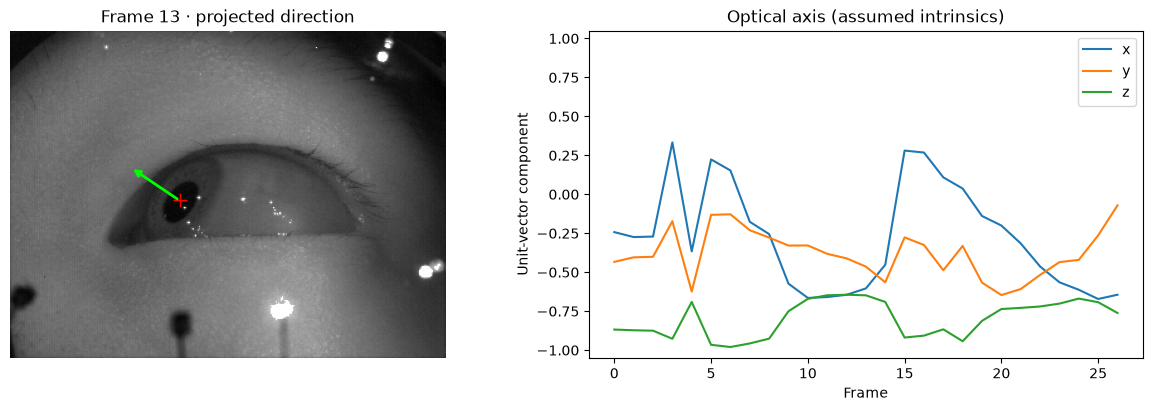

In [ ]:
# One eye, one fixed camera mounting. Outputs are in the OpenCV eye-camera frame:
# +x right in the image, +y down, +z from the camera into the scene.
# This circular-pupil/pinhole model approximates the apparent pupil. Corneal
# refraction can bias its orientation. Absolute eye-center depth needs a scale measurement.
from pathlib import Path
import cv2
import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares
from scipy.spatial.transform import Rotation
from tensorflow import keras

RECORDING = Path("_/Data_davis_labelled_with_mask/left/user1_session_2_0_2.h5")
CHECKPOINT = Path("_/best.keras")
K_MEASURED = None  # Replace with np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]]) in pixels.
DIST = None       # OpenCV distortion coefficients for this camera; None assumes zero distortion.
FIXATIONS = {}    # {frame_index: [gx, gy, gz]}: known eye-to-target DIRECTIONS in camera coordinates.
MAX_RADIAL_ERROR = 0.20  # Reject markedly nonelliptical contours (90th-percentile fractional error).


def pupil_geometry(mask, K, dist):
    
    """Return the eye-center plane, both candidate normals, and both pupil-center rays."""
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    
    if not contours:
    
        return None
    
    border = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(border)
    if (len(border) < 5 or cv2.contourArea(border) == 0 or x == 0 or y == 0
    
            or x + w == mask.shape[1] or y + h == mask.shape[0]):
    
        return None

    points = border.astype(np.float32)
    if dist is not None:
    
        points = cv2.undistortPoints(points, K, dist, P=K)
    
    try:
    
        center, diameters, angle = cv2.fitEllipse(points)
    
    except cv2.error:
    
        return None
    
    radii = np.asarray(diameters) / 2
    if not np.isfinite([*center, *radii, angle]).all() or min(radii) <= 0:
    
        return None
    
    angle = np.deg2rad(angle)
    c, s = np.cos(angle), np.sin(angle)
    R = np.array([[c, s], [-s, c]])  # Image axes -> ellipse axes
    local = (points[:, 0] - center) @ R.T / radii
    
    if np.percentile(np.abs(np.linalg.norm(local, axis=1) - 1), 90) > MAX_RADIAL_ERROR:
    
        return None

    # A camera ray v hits the apparent ellipse boundary when v.T @ Q @ v == 0.
    T = np.eye(3)
    T[:2, :2], T[:2, 2] = R, -R @ center
    B = T @ K
    Q = B.T @ np.diag([1/radii[0]**2, 1/radii[1]**2, -1]) @ B
    (lo, mid, hi), V = np.linalg.eigh(Q)
    
    if not lo < 0 < mid:
    
        return None
    
    a, b = np.sqrt(np.maximum([hi - mid, mid - lo], 0) / (hi - lo))
    normals = b * V[:, 0] + np.array([[a], [-a]]) * V[:, 2]
    rays = np.linalg.solve(Q, normals.T).T
    
    if np.any(np.abs(rays[:, 2]) < 1e-12):
    
        return None
    
    rays = rays / rays[:, 2:3]  # Positive depth, expressed at z = 1
    normals[np.sum(normals * rays, axis=1) > 0] *= -1  # Visible side faces the camera
    
    return a * V[:, 1], normals, rays


def fit_directions(obs, n_frames, focal_px):
    
    """Fit a shared eye center up to scale, then resolve each pupil normal."""
    if len(obs) < 2:
    
        raise ValueError("Too few usable ellipses. Use more frames of this same eye and camera mounting.")
    
    planes = np.stack([o[0] for o in obs.values()])
    A, rhs = planes[:, :2], -planes[:, 2]
    xy, _, rank, sv = np.linalg.lstsq(A, rhs, rcond=None)
    
    if rank < 2 or sv[1] <= 1e-6 * sv[0]:
    
        raise ValueError("The eye-center geometry is degenerate. Use frames with different gaze directions.")
    
    if sv[1] < 0.05 * sv[0]:
    
        print("Weak eye-center estimate: most observations constrain the same direction.")
    
    xy = least_squares(lambda p: A @ p - rhs, xy, loss="soft_l1", f_scale=1/focal_px).x
    eye = np.r_[xy, 1.]  # Gauge choice: absolute eye depth is unknown.
    directions = np.full((n_frames, 3), np.nan)
    center_rays = np.full_like(directions, np.nan)
    
    for t, (_, normals, rays) in obs.items():
    
        if np.linalg.norm(normals[0] - normals[1]) < 1e-6:
            directions[t], center_rays[t] = normals[0], rays[0]
            continue
    
        physical = []
    
        for j, (n, r) in enumerate(zip(normals, rays)):
    
            # depth*r = eye + offset*n: the pupil is in front of the center along its outward normal.
            (depth, offset), _, rank, _ = np.linalg.lstsq(np.column_stack((r, -n)), eye, rcond=None)
    
            if rank == 2 and depth > 0 and offset > 0:
    
                physical.append(j)
    
        if len(physical) == 1:
    
            j = physical[0]
            directions[t], center_rays[t] = normals[j], rays[j]
    
    return eye, directions, center_rays


def calibrate(optical, fixations):
    
    """Empirical per-eye rotation from optical directions to known fixation directions."""
    if not fixations:
    
        return None
    
    ids = np.asarray(list(fixations), dtype=int)
    if np.any(ids < 0) or np.any(ids >= len(optical)):
    
        raise ValueError("A fixation frame index is outside this recording.")
    
    targets = np.asarray([fixations[t] for t in ids], dtype=float)
    if targets.shape != (len(ids), 3) or not np.isfinite(targets).all() or np.any(np.linalg.norm(targets, axis=1) == 0):
    
        raise ValueError("Each fixation must be a finite, nonzero 3D eye-to-target direction.")
    
    valid = np.isfinite(optical[ids]).all(axis=1)
    src, dst = optical[ids[valid]], targets[valid]
    dst = dst / np.linalg.norm(dst, axis=1, keepdims=True)
    
    if len(src) < 2 or min(np.linalg.matrix_rank(src), np.linalg.matrix_rank(dst)) < 2:
    
        raise ValueError("Calibration needs at least two usable, non-collinear fixation directions.")
    
    rotation, _ = Rotation.align_vectors(dst, src)
    
    return optical @ rotation.as_matrix().T


model = keras.models.load_model(CHECKPOINT, compile=False)
with h5py.File(RECORDING, "r") as f:
    
    data = f["data"]  # W,H,T on disk
    W, H, N = data.shape
    
    if tuple(model.input_shape[1:]) != (H, W, 1):
    
        raise ValueError(f"The transposed frames are {(H, W, 1)}; the model expects {model.input_shape[1:]}.")
    
    demo = K_MEASURED is None
    if demo and DIST is not None:
    
        raise ValueError("Supply the measured camera matrix that belongs to these distortion coefficients.")
    
    K = (np.array([[W, 0, (W-1)/2], [0, W, (H-1)/2], [0, 0, 1.]], dtype=float)
    
         if demo else np.asarray(K_MEASURED, dtype=float))
    
    if (K.shape != (3, 3) or not np.isfinite(K).all() or min(K[0,0], K[1,1]) <= 0
            or not np.allclose(K[2], [0, 0, 1])):
        raise ValueError("Use a valid 3x3 camera matrix at this frame resolution.")
    
    dist = None if DIST is None else np.asarray(DIST, dtype=float)
    if demo:
    
        print(f"DEMO intrinsics: assuming fx = fy = {W} px and a centered principal point.")
    
    obs = {}
    for t in range(N):
    
        frame = np.asarray(data[:, :, t].T, dtype=np.float32)
        probability = model(frame[None, :, :, None], training=False).numpy()[0, :, :, 0]
        geometry = pupil_geometry((probability >= 0.5).astype(np.uint8), K, dist)
    
        if geometry is not None:
    
            obs[t] = geometry


eye_center_scaled, optical_cam, pupil_center_ray = fit_directions(obs, N, (K[0,0] + K[1,1])/2)
gaze_cam = calibrate(optical_cam, FIXATIONS)
vectors = optical_cam if gaze_cam is None else gaze_cam
label = "Optical axis" if gaze_cam is None else "Fixation-calibrated gaze"

if demo:

    label += " (assumed intrinsics)"

valid_frames = np.flatnonzero(np.isfinite(vectors).all(axis=1))
print(f"{label}: {len(valid_frames)}/{N} frames resolved. Missing or ambiguous frames contain NaN.")

if len(valid_frames):
   
    t = int(valid_frames[len(valid_frames)//2])
    print(f"Frame {t}: {vectors[t].round(4)}")
   
    with h5py.File(RECORDING, "r") as f:
   
        example = f["data"][:, :, t].T
   
    ray = pupil_center_ray[t]
    segment = np.stack([ray, ray + 0.15 * ray[2] * vectors[t]])
    uv = cv2.projectPoints(segment, np.zeros(3), np.zeros(3), K, dist)[0][:, 0]
   
    fig, (ax, trace) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    ax.imshow(example, cmap="gray")
    ax.plot(*uv[0], "r+", ms=10)
    ax.annotate("", xy=uv[1], xytext=uv[0], arrowprops=dict(arrowstyle="->", color="lime", lw=2))
    ax.set(xlim=(-.5, W-.5), ylim=(H-.5, -.5), title=f"Frame {t} · projected direction")
    ax.axis("off")
    trace.plot(vectors)
    trace.legend(["x", "y", "z"])
    trace.set(xlabel="Frame", ylabel="Unit-vector component", title=label, ylim=(-1.05, 1.05))
    plt.show()

Test gaze prediction over a batch of samples

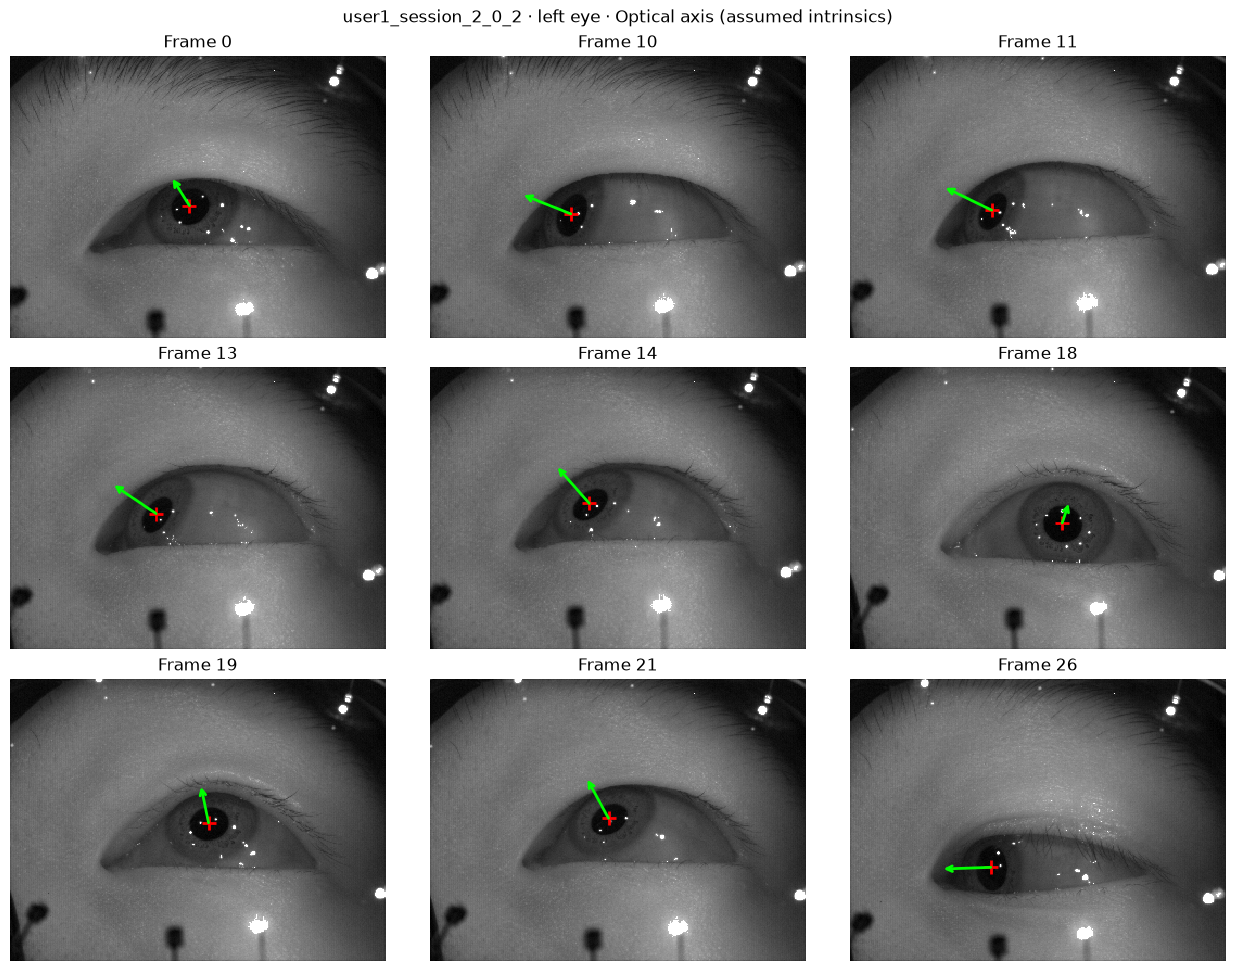

In [ ]:
N_SHOW = 9
rng = np.random.default_rng()  # Use np.random.default_rng(42) for a repeatable batch

valid = np.flatnonzero(
    np.isfinite(vectors).all(axis=1) & np.isfinite(pupil_center_ray).all(axis=1)
)

if not len(valid):

    raise ValueError("No frames with a resolved direction in this recording.")

chosen = np.sort(rng.choice(valid, size=min(N_SHOW, len(valid)), replace=False))

ncols = min(3, len(chosen))
nrows = (len(chosen) + ncols - 1) // ncols
fig, axes = plt.subplots(
    nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows),
    squeeze=False, constrained_layout=True,
)

for ax in axes.flat:

    ax.axis("off")


with h5py.File(RECORDING, "r") as f:

    data = f["data"]

    for ax, t in zip(axes.flat, chosen):

        frame = data[:, :, int(t)].T
        center = pupil_center_ray[t]
        direction = vectors[t]

        # Project a short segment along the estimated 3D direction.
        tip = center + 0.15 * center[2] * direction
        pixels, _ = cv2.projectPoints(
            np.stack([center, tip]), np.zeros(3), np.zeros(3), K, dist
        )
        start_xy, end_xy = pixels.reshape(2, 2)

        ax.imshow(frame, cmap="gray", interpolation="nearest")
        ax.annotate(
            "", xy=end_xy, xytext=start_xy,
            arrowprops=dict(arrowstyle="->", color="lime", lw=2,
                            shrinkA=0, shrinkB=0),
        )
        ax.plot(*start_xy, "r+", markersize=10, markeredgewidth=2)
        ax.set_xlim(-0.5, frame.shape[1] - 0.5)
        ax.set_ylim(frame.shape[0] - 0.5, -0.5)
        ax.set_title(f"Frame {t}")

fig.suptitle(f"{RECORDING.stem} · {RECORDING.parent.name} eye · {label}")
plt.show()